In [1]:
import logging, warnings
import numpy as np, pandas as pd
from pathlib import Path
from scipy.stats import spearmanr, ConstantInputWarning
from tqdm import tqdm
from umap import UMAP
from dtaidistance import dtw
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
import pathlib
import importlib

from mtsspi.utils import iter_dataset_dirs, load_json
from mtsspi.plot_style import apply_plot_style
from mtsspi.visualization import plot_mts_corr_density, plot_spi_space_individual, plot_pca, plot_umap, plot_tsne

apply_plot_style()
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
warnings.simplefilter("ignore", ConstantInputWarning)


/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Exploratory and making the system

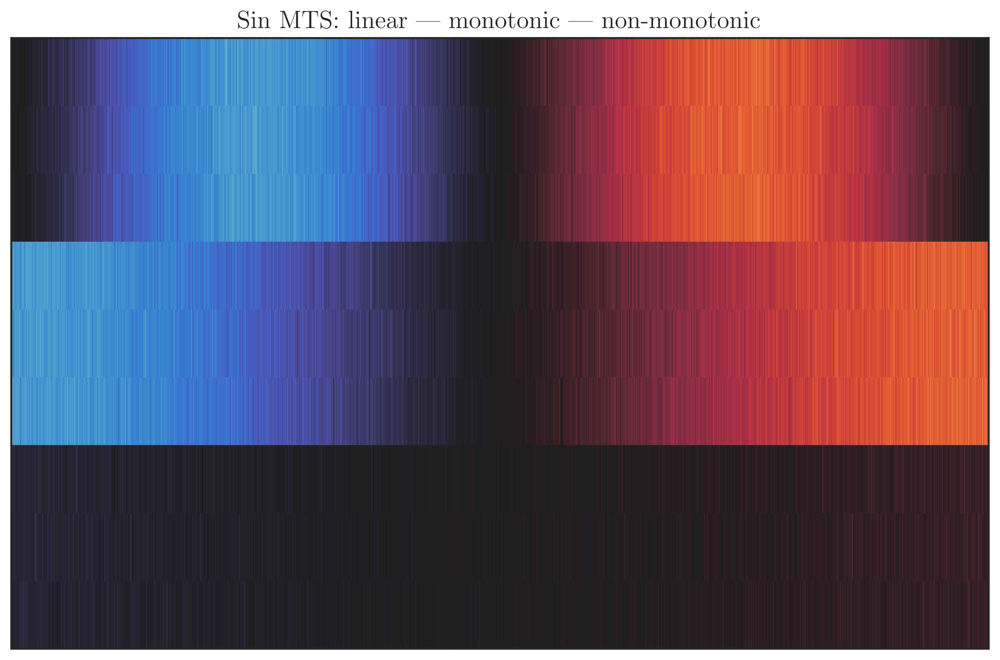

In [2]:
import numpy as np
from mtsspi.visualization import plot_mts_heatmap

# --- Parameters ---
M, T = 9, 1000
noise_std = 0.05

# Regime intervals for sin(t)
regimes = {
    "linear":     (-np.pi / 16, np.pi / 16),   # channels 0-2
    "monotonic":  (-np.pi / 2, np.pi / 2),    # channels 3-5
    "non-monotonic": (-np.pi, np.pi),          # channels 6-8
}

# Channel-to-regime assignment
channel_regimes = ["linear"] * 3 + ["monotonic"] * 3 + ["non-monotonic"] * 3

# --- Generate MTS (M x T) ---
mts = np.empty((M, T))
for i, regime in enumerate(channel_regimes):
    lo, hi = regimes[regime]
    t = np.linspace(lo, hi, T)
    mts[i] = np.sin(t) + np.random.default_rng(seed=i).normal(0, noise_std, T)

# --- Plot ---
plot_mts_heatmap(mts, title="Sin MTS: linear | monotonic | non-monotonic", vmin=-1.5, vmax=1.5)

(9, 100)


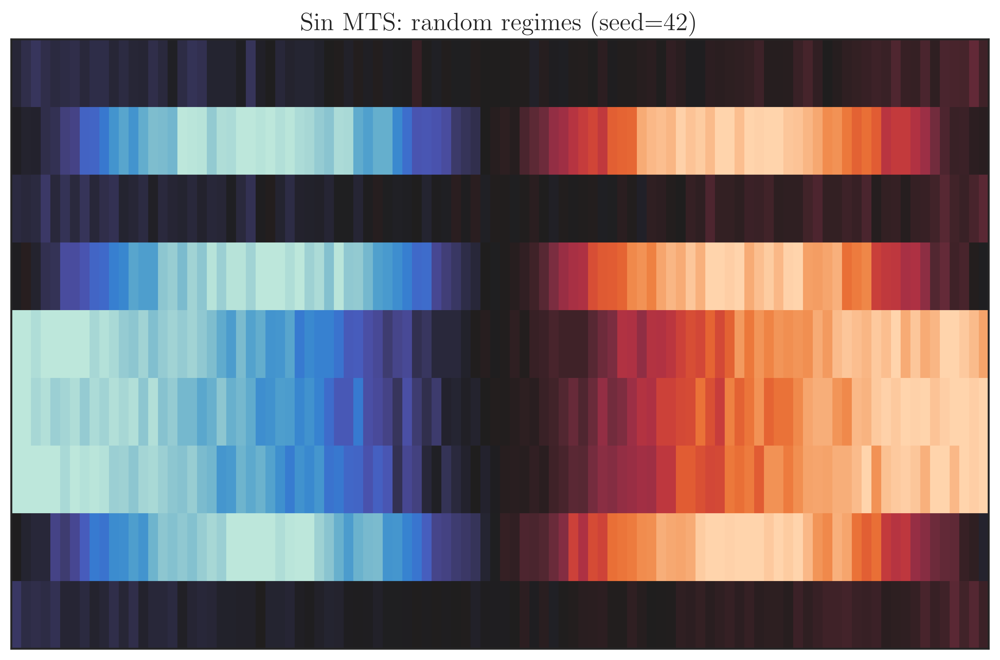

In [3]:

SEED = 42
M, T = 9, 100
noise_std = 0.05

regime_intervals = [
    (-np.pi / 16, np.pi / 16),  # 0: linear
    (-np.pi / 2,  np.pi / 2),   # 1: monotonic nonlinear
    (-np.pi,      np.pi),        # 2: non-monotonic nonlinear
]

rng = np.random.default_rng(SEED)
regime_ids = rng.integers(0, 3, size=M)  # roll in {0, 1, 2} per channel

mts_rand = np.empty((M, T))
for i, rid in enumerate(regime_ids):
    lo, hi = regime_intervals[rid]
    t = np.linspace(lo, hi, T)
    mts_rand[i] = np.sin(t) + rng.normal(0, noise_std, T)

print(mts_rand[:,:].shape)
regime_labels = {0: "linear", 1: "monotonic", 2: "non-monotonic"}

plot_mts_heatmap(mts_rand, title=f"Sin MTS: random regimes (seed={SEED})", vmin=-1, vmax=1)


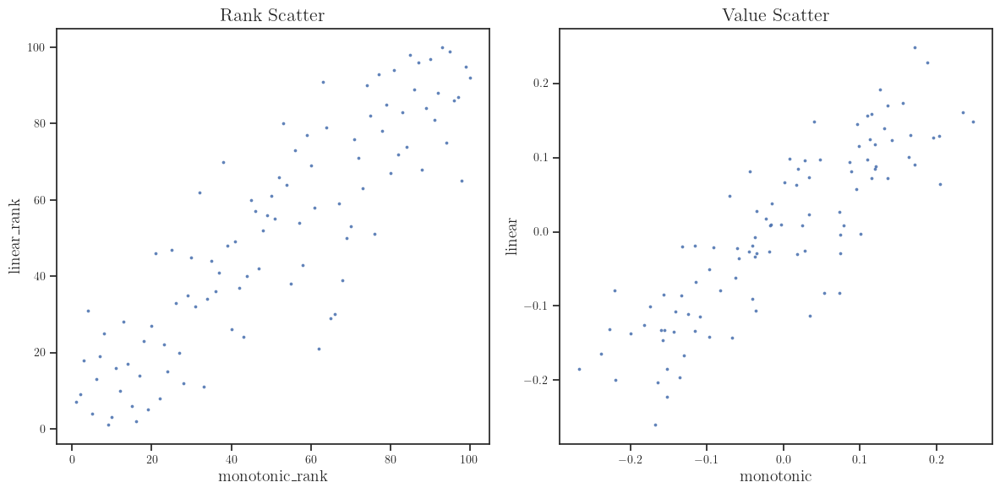

In [4]:
from scipy.stats import rankdata, gaussian_kde

linear_rank = rankdata(mts_rand[0])
monotonic_rank = rankdata(mts_rand[6])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].scatter(monotonic_rank, linear_rank, s=3, alpha=0.8)
axes[0].set_xlabel("monotonic_rank")
axes[0].set_ylabel("linear_rank")
axes[0].set_title("Rank Scatter")
axes[1].scatter(mts_rand[6], mts_rand[0], s=3, alpha=0.8)
axes[1].set_xlabel("monotonic")
axes[1].set_ylabel("linear")
axes[1].set_title("Value Scatter")
for i in range(2):
    axes[i].set_aspect('auto')
plt.tight_layout()

#### Having a look at some different MTS made - fixed-linear, fixed-monotonic, fixed-non-monotonic, and random channels

---

#### DO NOT RID

#### Fixed + Random in large size




/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.









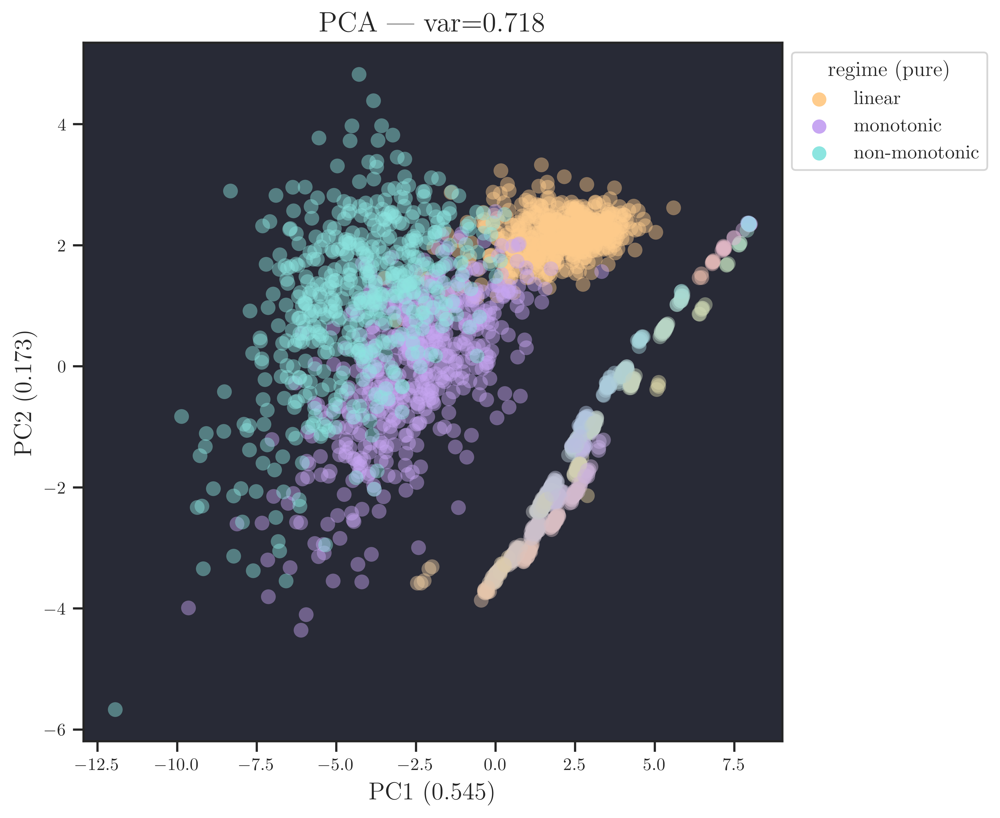

/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



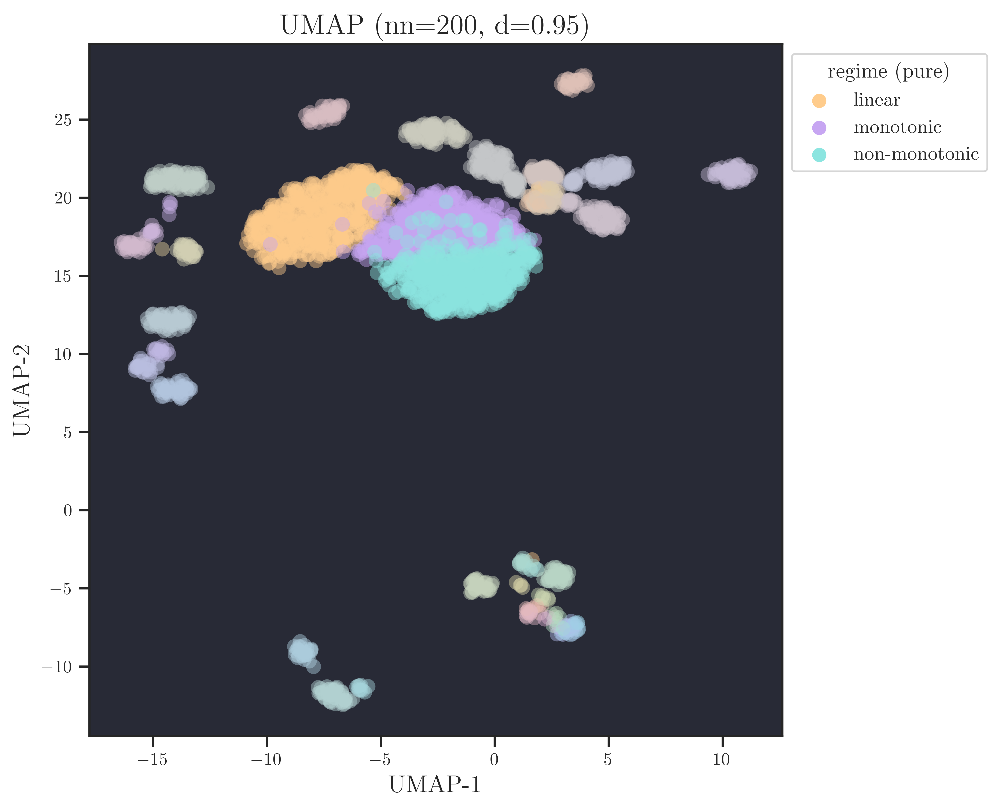

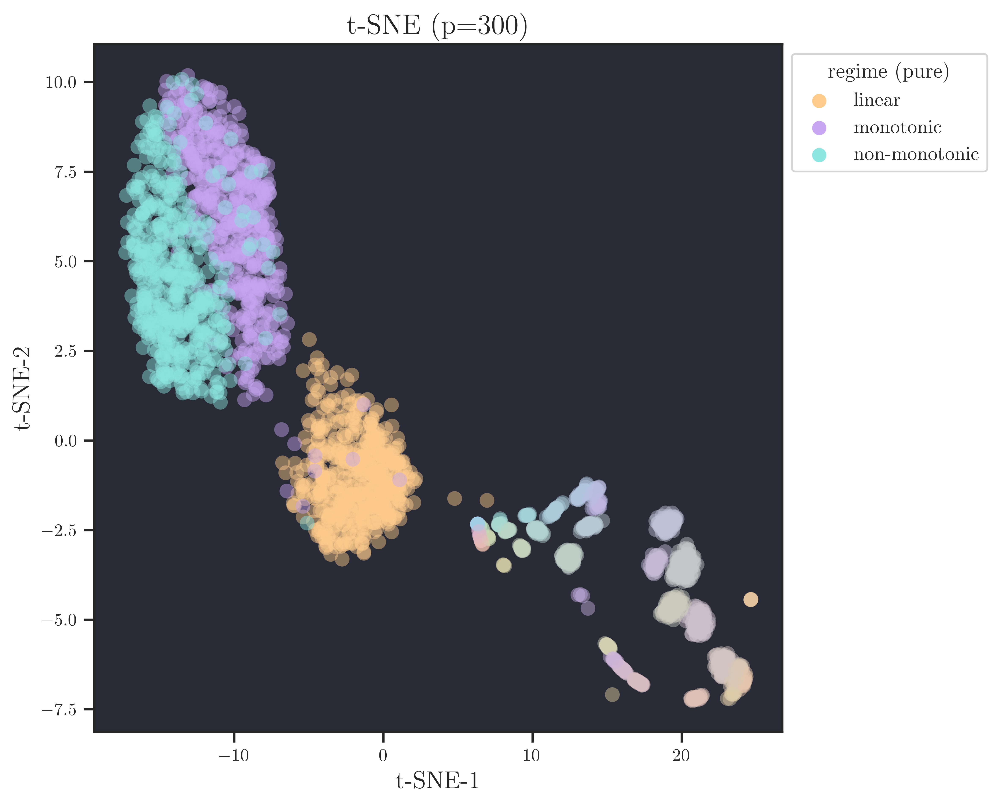

array([[-1.4419472 , -2.878982  ],
       [ 0.1319485 , -1.0732123 ],
       [-0.65180016, -0.927123  ],
       ...,
       [15.564062  , -6.158335  ],
       [19.882053  , -4.4963303 ],
       [ 6.5299706 , -2.7917898 ]], shape=(2500, 2), dtype=float32)

In [44]:
import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (
    regime_colors,
    plot_regime_embedding,          # Option 2: single plot, mixed OPT colors
    plot_regime_embedding_triple,   # Option 1: 3 subplots, one per proportion
    plot_ternary_regime,            # Option 3: ternary diagram
    plot_pca,                       # categorical hue (mts_class)
)

cache = project_root() / "analysis" / "feature_cache" / "data-sin_mts_fixed_random_pearson.npz"
data  = np.load(cache, allow_pickle=True)
X, y, paths = data["X"], data["y"], data["dataset_paths"]
meta_df = pd.DataFrame({"mts_class": y, "M": data["M"].astype(int), "T": data["T"].astype(int)})
props = regime_colors(paths)   # (N, 3) proportions

# Option 1 — workhorse: unambiguous per-proportion readout
emb = plot_regime_embedding_triple(X, props, method="pca", meta_df=meta_df)
emb = plot_regime_embedding_triple(X, props, method="umap", meta_df=meta_df, n_neighbors=200, min_dist=0.95)
emb = plot_regime_embedding_triple(X, props, method="tsne", meta_df=meta_df, perplexity=300)


# Option 2 — compact summary: mixed anchor colors
colors = regime_colors(paths)
plot_regime_embedding(X, colors, method="pca",  meta_df=meta_df, alpha=0.45)
plot_regime_embedding(X, colors, method="umap", meta_df=meta_df, alpha=0.45, n_neighbors=200, min_dist=0.95)
plot_regime_embedding(X, colors, method="tsne", meta_df=meta_df, alpha=0.45, perplexity=300)


# # Option 3 — regime coverage: where are datasets in the 3-simplex?
# plot_ternary_regime(props, meta_df=meta_df, hue_col="mts_class")

# # Baseline: categorical class separation
# plot_pca(X, meta_df, hue="mts_class", size_col="M")


#### Only random




/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.









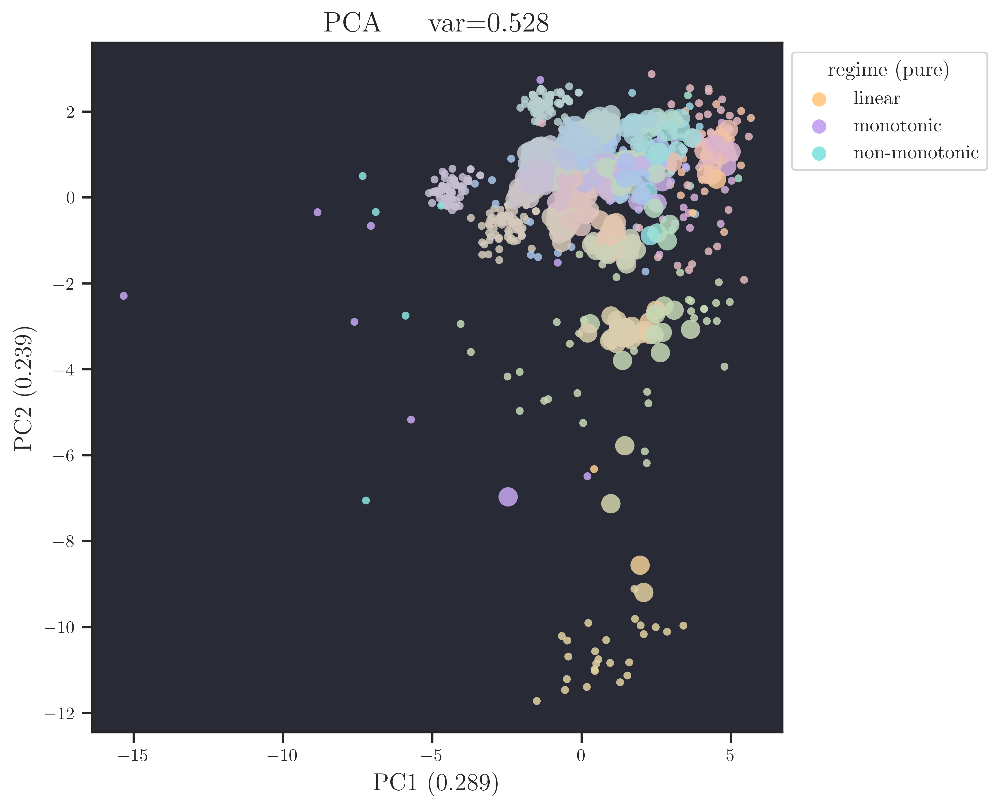

/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



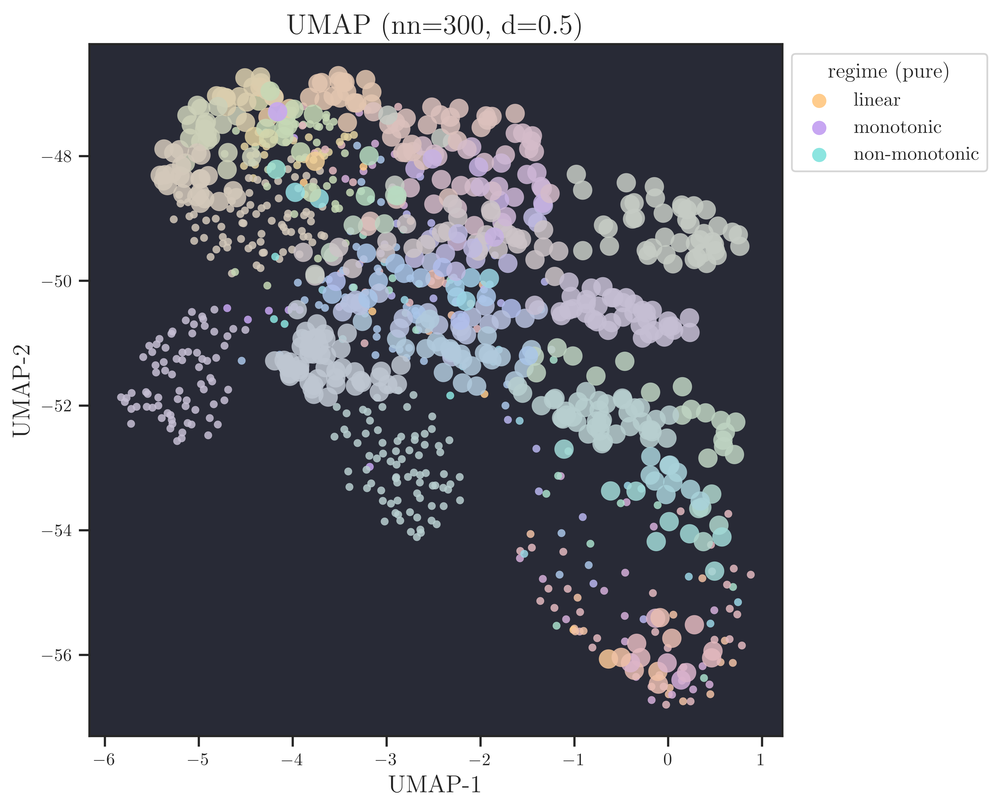

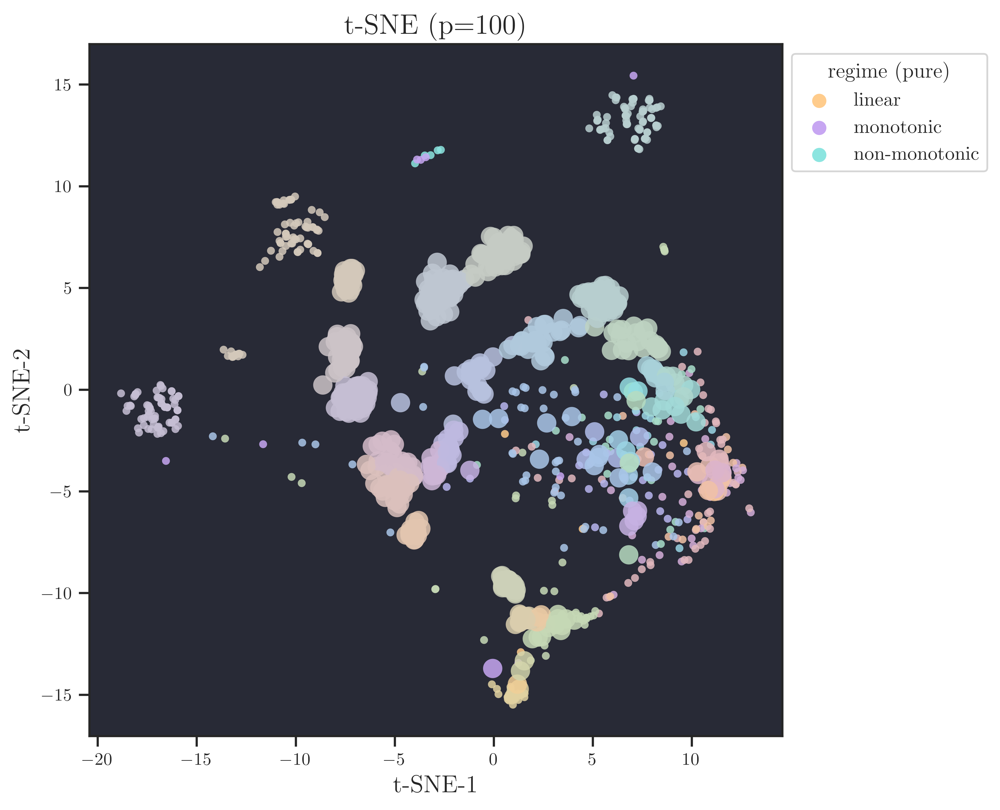

array([[ 12.218532  ,  -4.6337867 ],
       [  4.141581  , -10.957473  ],
       [  7.821163  ,  14.220666  ],
       ...,
       [ -7.2270293 ,  -0.25577906],
       [  6.2250385 ,   4.2536206 ],
       [ -1.1650871 ,   1.0268292 ]], shape=(1024, 2), dtype=float32)

In [41]:
import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (
    regime_colors,
    plot_regime_embedding,          # Option 2: single plot, mixed OPT colors
    plot_regime_embedding_triple,   # Option 1: 3 subplots, one per proportion
    plot_ternary_regime,            # Option 3: ternary diagram
    plot_pca,                       # categorical hue (mts_class)
)

cache = project_root() / "analysis" / "feature_cache" / "data-sin_mts_random_only_spearman.npz"
data  = np.load(cache, allow_pickle=True)
X, y, paths = data["X"], data["y"], data["dataset_paths"]
meta_df = pd.DataFrame({"mts_class": y, "M": data["M"].astype(int), "T": data["T"].astype(int)})
props = regime_colors(paths)   # (N, 3) proportions

# Option 1 — workhorse: unambiguous per-proportion readout
emb = plot_regime_embedding_triple(X, props, method="pca", meta_df=meta_df)
emb = plot_regime_embedding_triple(X, props, method="umap", meta_df=meta_df, n_neighbors=20, min_dist=0.95)
emb = plot_regime_embedding_triple(X, props, method="tsne", meta_df=meta_df, perplexity=30)


# Option 2 — compact summary: mixed anchor colors
colors = regime_colors(paths)
plot_regime_embedding(X, colors, method="pca",  meta_df=meta_df, alpha=0.85)
plot_regime_embedding(X, colors, method="umap", meta_df=meta_df, alpha=0.85, n_neighbors=300, min_dist=0.5)
plot_regime_embedding(X, colors, method="tsne", meta_df=meta_df, alpha=0.85, perplexity=100)


# # Option 3 — regime coverage: where are datasets in the 3-simplex?
# plot_ternary_regime(props, meta_df=meta_df, hue_col="mts_class")

# # Baseline: categorical class separation
# plot_pca(X, meta_df, hue="mts_class", size_col="M")


#### Processing `SinMTS_*`

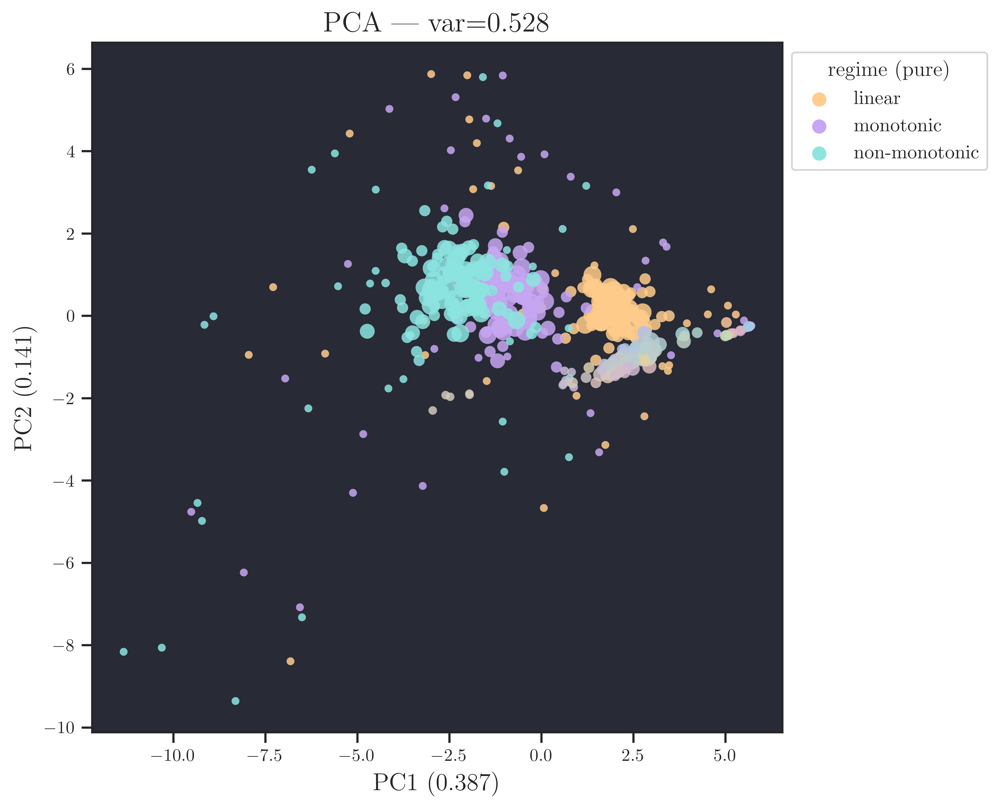

/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



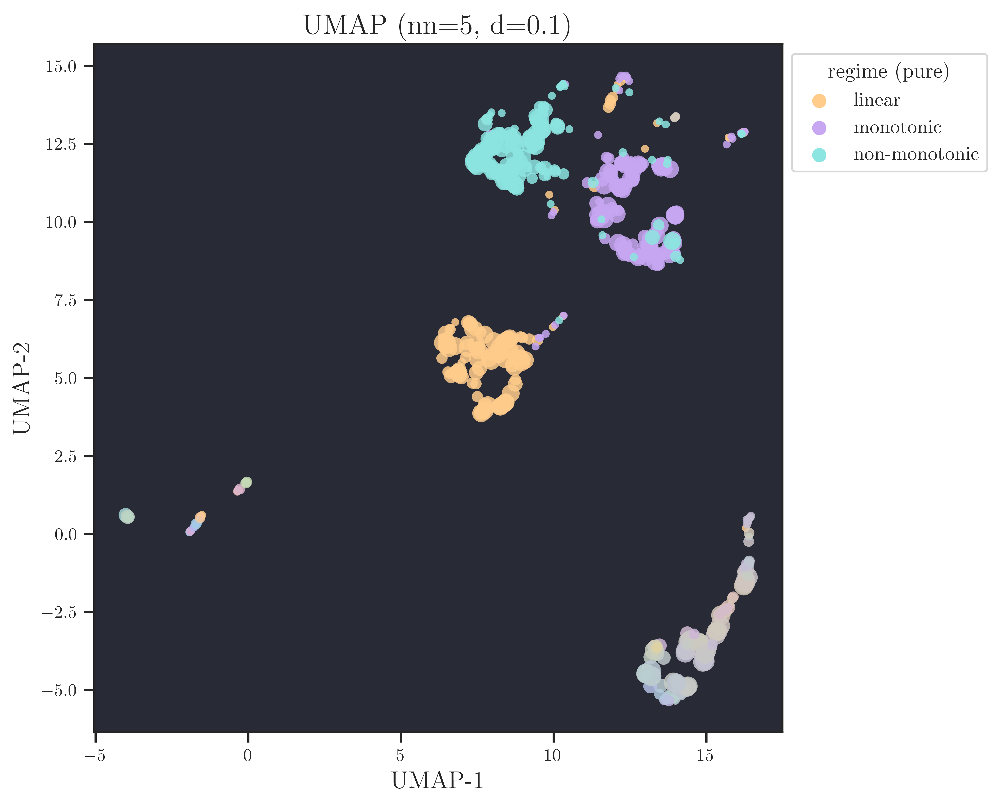

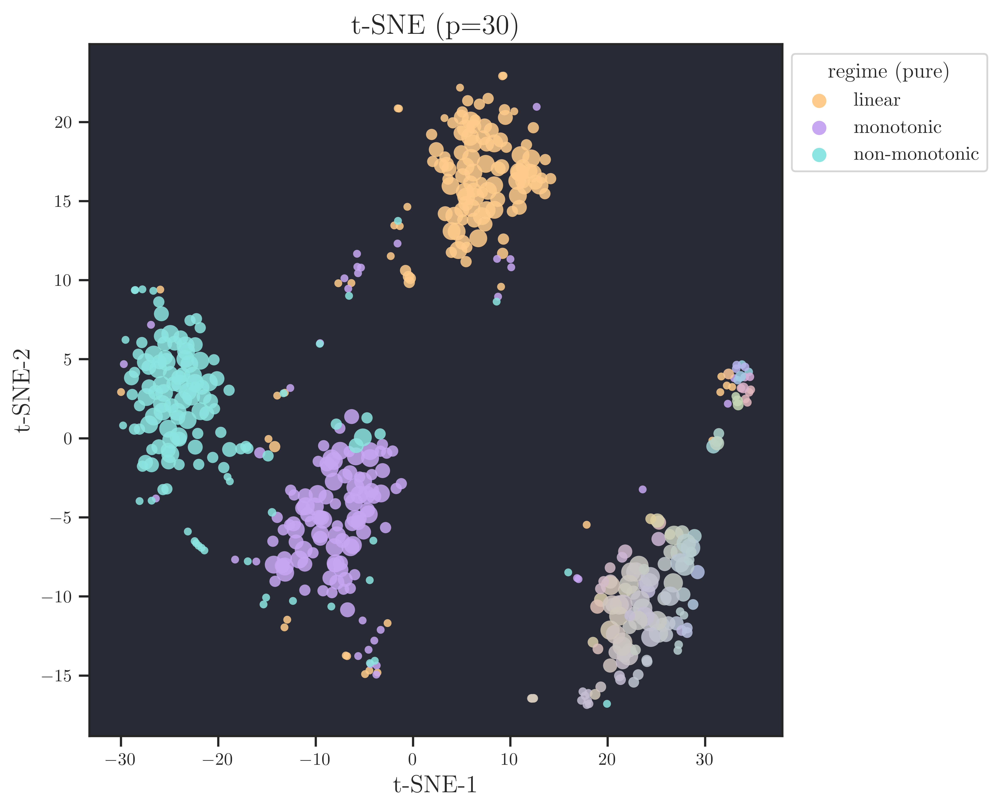

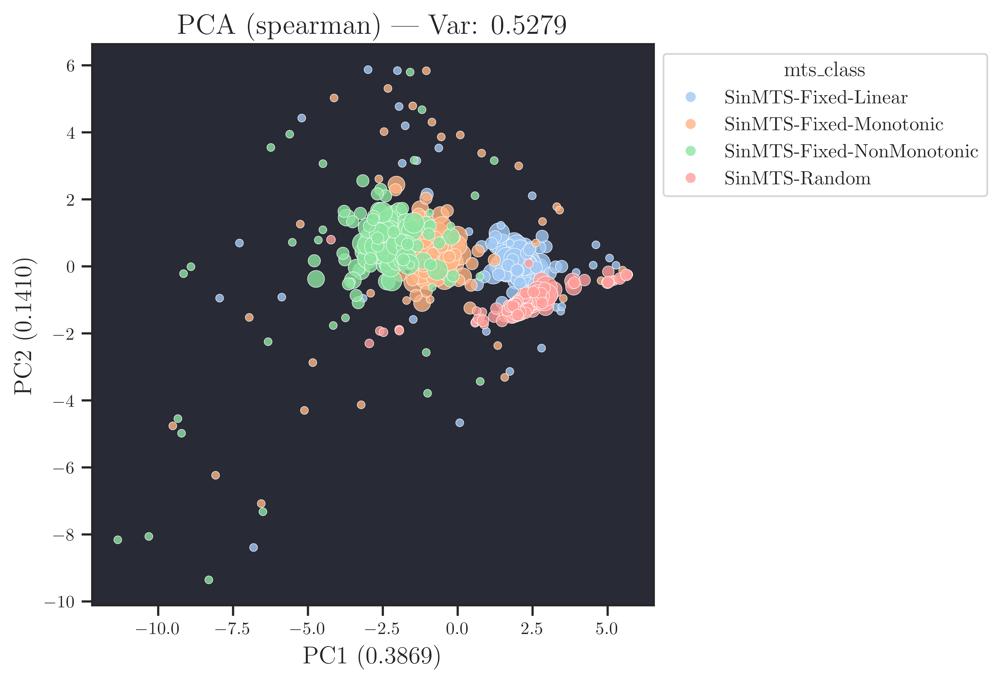

array([[ 1.5793319 , -0.00266077],
       [ 2.4832506 , -0.15935177],
       [ 1.4014577 ,  0.10487029],
       ...,
       [ 1.8383217 , -1.180201  ],
       [ 1.4789013 , -1.626777  ],
       [ 1.9999171 , -1.4541304 ]], shape=(512, 2), dtype=float32)

In [29]:
import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import regime_colors, plot_regime_embedding, plot_spi_space_individual, plot_mts_corr_density, plot_spi_space_recursive

# Load cache
cache = project_root() / "analysis" / "feature_cache" / "data-sin_mts_test_pearson.npz"
data = np.load(cache, allow_pickle=True)

X     = data["X"]
y     = data["y"]
paths = data["dataset_paths"]
Ms    = data["M"].astype(int)
Ts    = data["T"].astype(int)

meta_df = pd.DataFrame({"mts_class": y, "M": Ms, "T": Ts})

# --- Colored by regime proportions (R=linear, G=monotonic, B=non-monotonic) ---
colors = regime_colors(paths)
plot_regime_embedding(X, colors, method="pca",  meta_df=meta_df, alpha=0.85)
plot_regime_embedding(X, colors, method="umap", meta_df=meta_df, alpha=0.85, n_neighbors=5, min_dist=0.1)
plot_regime_embedding(X, colors, method="tsne", meta_df=meta_df, alpha=0.85, perplexity=30)

# --- Colored by mts_class (categorical, for comparison) ---
plot_pca(X, meta_df, hue="mts_class", size_col="M", feature_space="spearman")





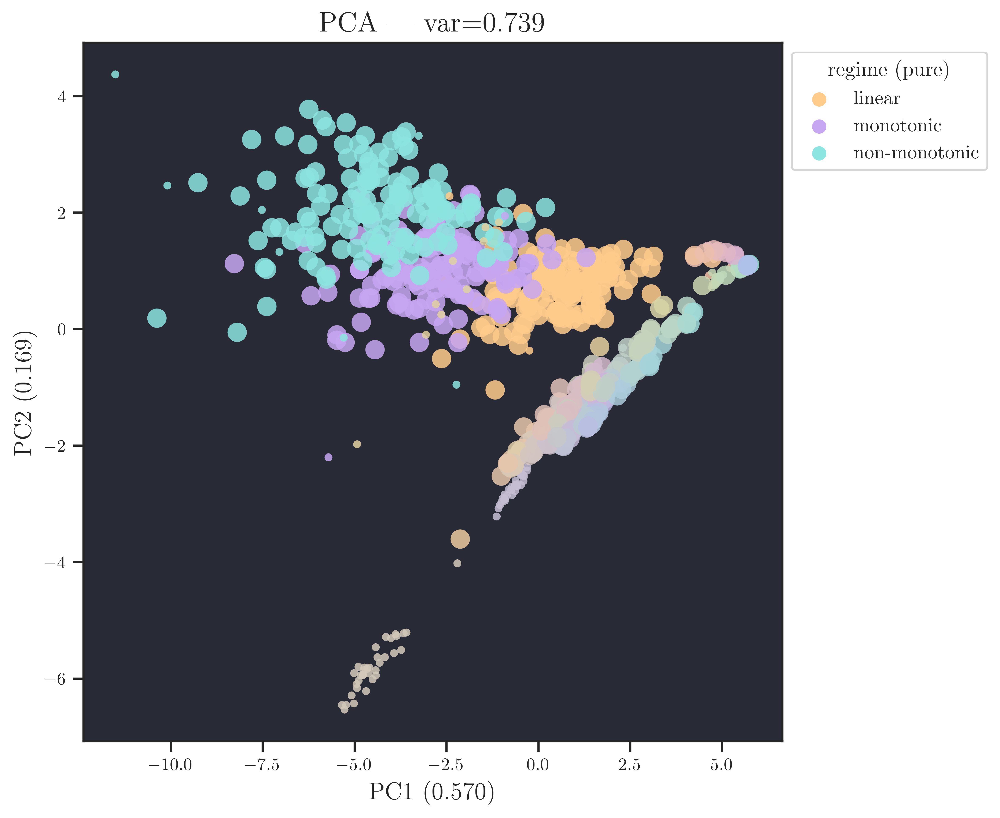

/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



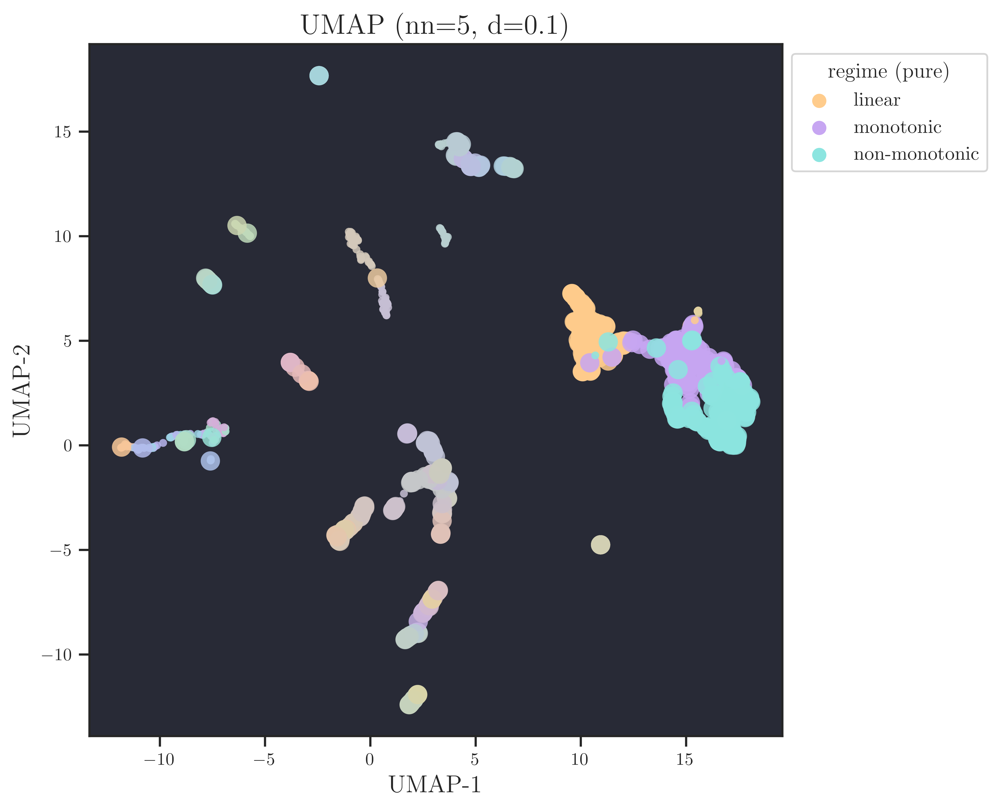

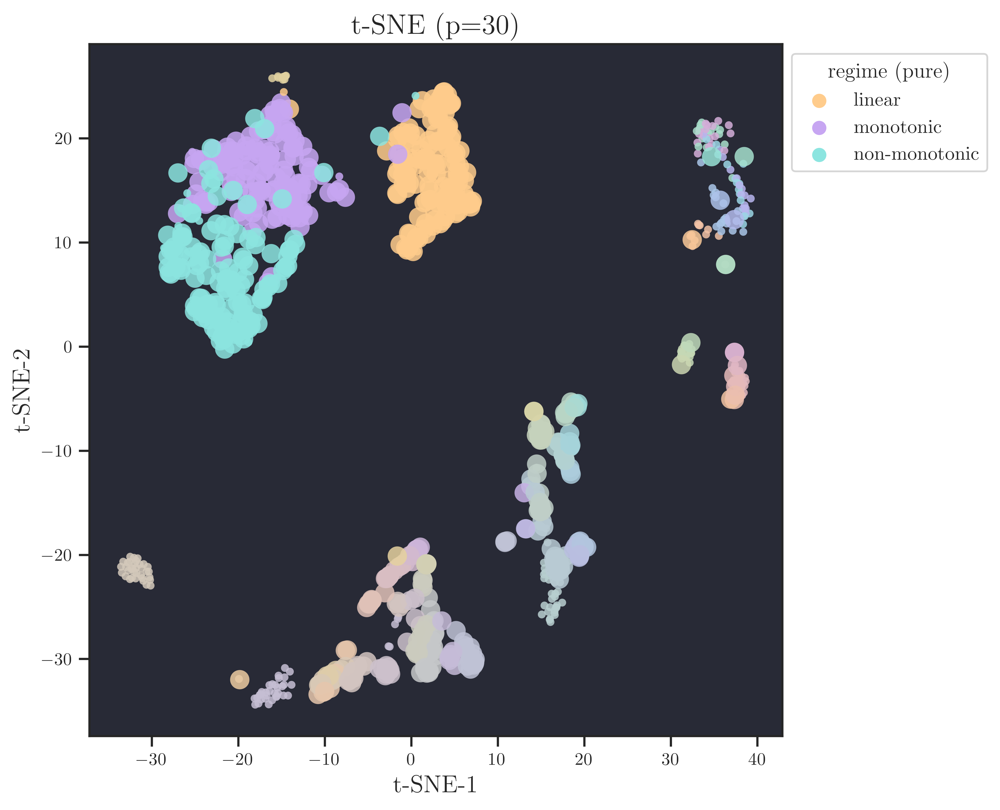

array([[ -0.26958883,   9.575461  ],
       [ -0.14743035,  10.81235   ],
       [  3.3253515 ,  11.810927  ],
       ...,
       [  1.7869055 , -31.34873   ],
       [ 18.439781  ,  -9.464511  ],
       [ 18.824312  ,  -5.8344946 ]], shape=(896, 2), dtype=float32)

In [30]:
import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import (
    regime_colors,
    plot_regime_embedding,          # Option 2: single plot, mixed OPT colors
    plot_regime_embedding_triple,   # Option 1: 3 subplots, one per proportion
    plot_ternary_regime,            # Option 3: ternary diagram
    plot_pca,                       # categorical hue (mts_class)
)

cache = project_root() / "analysis" / "feature_cache" / "data-sin_mts_small_pearson.npz"
data  = np.load(cache, allow_pickle=True)
X, y, paths = data["X"], data["y"], data["dataset_paths"]
meta_df = pd.DataFrame({"mts_class": y, "M": data["M"].astype(int), "T": data["T"].astype(int)})
props = regime_colors(paths)   # (N, 3) proportions

# Option 1 — workhorse: unambiguous per-proportion readout
emb = plot_regime_embedding_triple(X, props, method="pca", meta_df=meta_df)

# Option 2 — compact summary: mixed anchor colors
colors = regime_colors(paths)
plot_regime_embedding(X, colors, method="pca",  meta_df=meta_df, alpha=0.85)
plot_regime_embedding(X, colors, method="umap", meta_df=meta_df, alpha=0.85, n_neighbors=5, min_dist=0.1)
plot_regime_embedding(X, colors, method="tsne", meta_df=meta_df, alpha=0.85, perplexity=30)


# # Option 3 — regime coverage: where are datasets in the 3-simplex?
# plot_ternary_regime(props, meta_df=meta_df, hue_col="mts_class")

# # Baseline: categorical class separation
# plot_pca(X, meta_df, hue="mts_class", size_col="M")


In [17]:
import plotly.express as px
import pandas as pd

df = pd.DataFrame({
    "x": emb[:, 0], "y": emb[:, 1],
    "mts_class": y,
    "p_linear": props[:, 0].round(2),
    "p_monotonic": props[:, 1].round(2),
    "p_nm": props[:, 2].round(2),
    "M": meta_df["M"].to_numpy(),
    "T": meta_df["T"].to_numpy(),
})

fig = px.scatter(df, x="x", y="y", color="mts_class",
                 hover_data=["p_linear", "p_monotonic", "p_nm", "M", "T"],
                 opacity=0.85, width=1000, height=700)
fig.show()


#### Processing `SinMTS_Random`

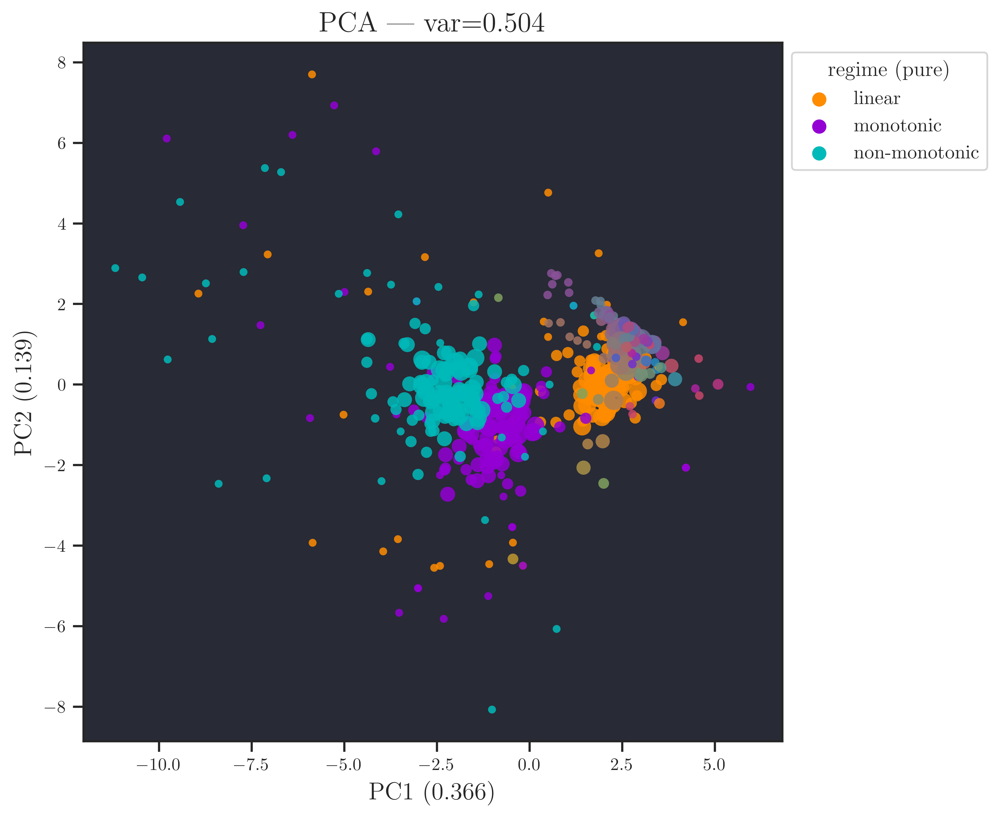

/Users/wedi0306/Library/CloudStorage/OneDrive-Personal/Desktop/2025USYD/USYD/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



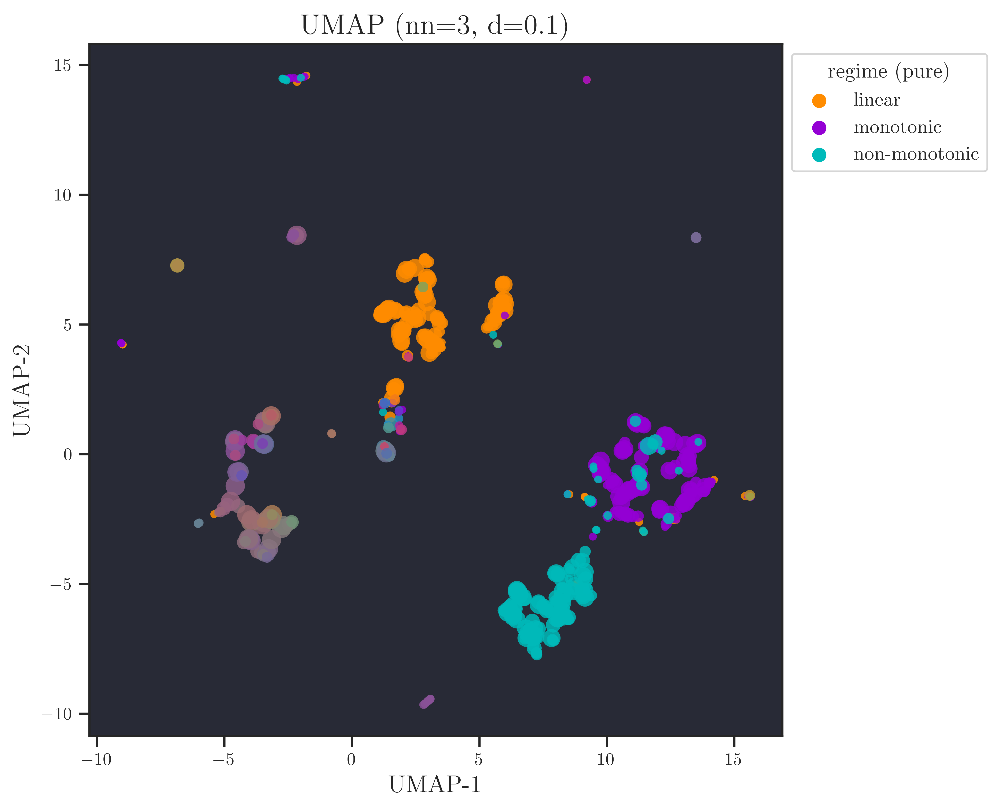

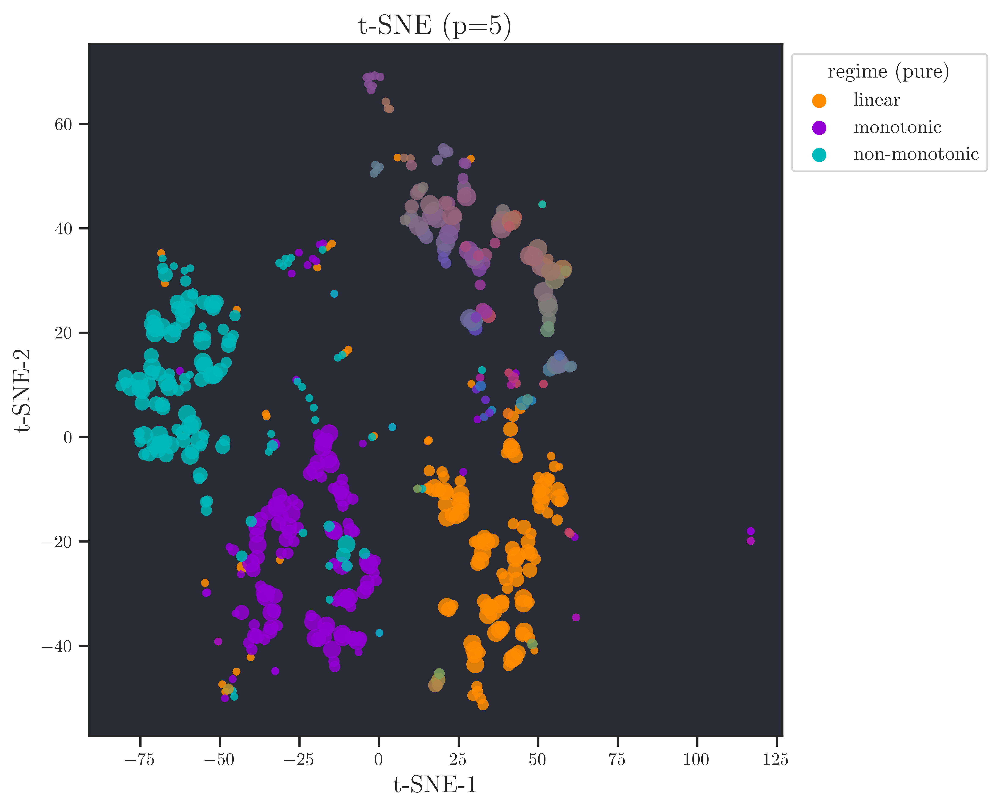

In [8]:
import numpy as np
import pandas as pd
from mtsspi.utils import project_root
import mtsspi.visualization
importlib.reload(mtsspi.visualization)
from mtsspi.visualization import regime_colors, plot_regime_embedding, plot_spi_space_individual, plot_mts_corr_density, plot_spi_space_recursive

# Load cache
cache = project_root() / "analysis" / "feature_cache" / "data-sin_mts_test_spearman.npz"
data = np.load(cache, allow_pickle=True)
X      = data["X"]
y      = data["y"]
Ms     = data["M"].astype(int)
Ts     = data["T"].astype(int)
paths  = data["dataset_paths"]

# Regime colors from l/m/nm in slug
colors = regime_colors(paths)

# Optional: DataFrame for M-based sizing
meta_df = pd.DataFrame({"M": Ms, "T": Ts, "mts_class": y})

# PCA
emb_pca = plot_regime_embedding(X, colors, method="pca", meta_df=meta_df)

# UMAP
emb_umap = plot_regime_embedding(X, colors, method="umap", meta_df=meta_df, n_neighbors=3, min_dist=0.1)

# t-SNE
emb_tsne = plot_regime_embedding(X, colors, method="tsne", meta_df=meta_df, perplexity=5)
